<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🧱 子 agent 与派单：治「乱」

**一句话定位**：子 agent = **一条消息进、一条消息出**的独立 agent；隔离 context 治 clash / confusion / poisoning / dilution。本课手写 `task` 工具，库里它叫 `SubAgentMiddleware`，灵魂一行没变。
> 对应主课 `3_a_🔥_subagents.ipynb` + 新课 m4.1–4.3、m5.4。本机 deepagents 0.7.28 源码对照。

</div>

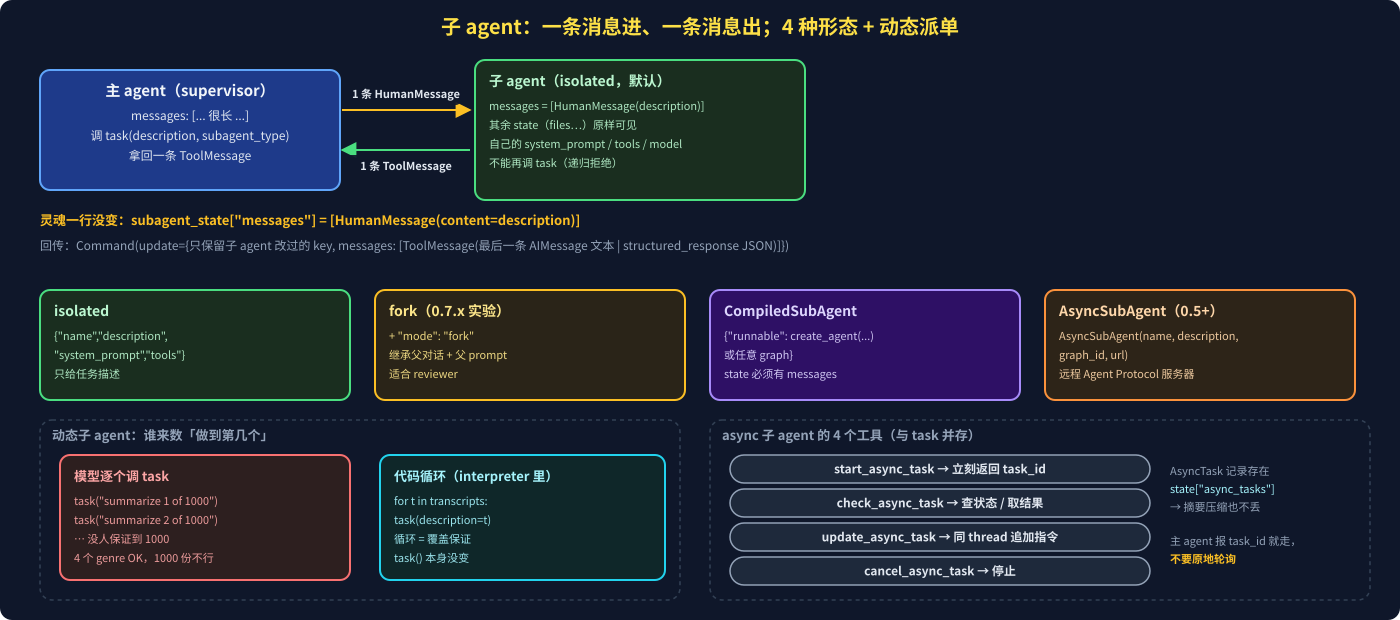

In [ ]:
from IPython.display import SVG
SVG(filename="assets/04_subagents.svg")

### 1️⃣ 为什么要隔离

| context 病 | 症状 | 隔离怎么治 |
|---|---|---|
| clash | 多目标互相矛盾 | 子 agent 只看到自己那一个任务 |
| confusion | 相似信息混淆 | 每个专家有自己的工具集，几十个工具描述不进主 context |
| poisoning | 错误信息污染后续推理 | 子 agent 的试错留在它自己的 context |
| dilution | 关键信息被噪音淹没 | 主 agent 只收一条**精简结论** |

《穿 Prada 的女魔头》类比：Miranda 不想听 Andy 怎么办到的，只要结果。子 agent = Andy。

### 2️⃣ 库版 `task` 内部（本课 ↔ 0.7.28）

| 本课 `_create_task_tool` | 库 `SubAgentMiddleware._build_task_tool` |
|---|---|
| `state: Annotated[..., InjectedState]` + `InjectedToolCallId` | `runtime: ToolRuntime` |
| `state["messages"] = [{"role": "user", "content": description}]` | `subagent_state["messages"] = [HumanMessage(content=description)]`；其余 state key（`files` 等）原样传入 |
| `Command(update={"files": result.get("files", {}), "messages": [ToolMessage(result["messages"][-1].content)]})` | `Command(update={**子 agent 改过的 key, "messages": [ToolMessage(最后一条非空 AIMessage 文本 或 structured_response JSON)]})` |
| 自己 `create_agent` 造子 agent | 每个子 agent 自动获得默认 middleware 栈：`FilesystemMiddleware → Summarization → PatchToolCalls (+ 该模型的 harness profile, + skills)` |

库特有：**子 agent 调 `task` 会被拒绝**（"You are a subagent and cannot delegate…"）；**总有一个 `general-purpose` 子 agent**，所以默认工具列表里一定有 `task`；并行 `task` 回传时**没改过的 key 被丢弃**，避免冲突。

In [ ]:
from deepagents import FilesystemPermission, create_deep_agent
from langchain.chat_models import init_chat_model
from langchain_core.tools import tool

model = init_chat_model("anthropic:claude-haiku-4-5")
strong_model = init_chat_model("anthropic:claude-sonnet-4-6")


@tool
def internet_search(query: str) -> str:
    """Search the web for recent news and return raw results."""
    return "..."  # Tavily 等


# 研究员只能写 /research/**；编辑可读不可写该目录（首个命中生效）
research_permissions = [
    FilesystemPermission(operations=["read", "write"], paths=["/research/**"], mode="allow"),
    FilesystemPermission(operations=["write"], paths=["/**"], mode="deny"),
]
editor_permissions = [FilesystemPermission(operations=["write"], paths=["/research/**"], mode="deny")]

genre_researcher = {                      # SubAgent：一个类型，派 4 次（genre 只是任务描述）
    "name": "genre-researcher",           # 主 agent 调 task(subagent_type=...) 用的名字
    "description": "Research one music genre and write a short newsletter segment. One genre per call.",
    "system_prompt": "You are a music journalist... save raw search output to /research/<genre>/sources.md, return ONLY the segment.",
    "tools": [internet_search],           # 覆盖自定义工具；内置文件工具始终都在
    "model": model,                       # 子 agent 可以用更便宜的模型
    "permissions": research_permissions,
}

editor = create_deep_agent(
    model=strong_model,
    system_prompt="You are the editor... delegate one task per genre in parallel, then assemble.",
    subagents=[genre_researcher],
    permissions=editor_permissions,
)

### 3️⃣ `SubAgent` 规格字段（0.7.28）

| 字段 | 必填 | 说明 |
|---|---|---|
| `name` `description` | ✅ | 主 agent 靠 description 决定派不派；description 要「具体、动作导向」 |
| `system_prompt` | | 子 agent 自己的脑子，**不继承**父 prompt（本课键名是 `prompt`，库里是 `system_prompt`） |
| `tools` | | **替换**继承的自定义工具（传工具对象）；内置文件工具不受影响；要裁文件工具用 `middleware=[FilesystemMiddleware(tools=[...])]` |
| `model` | | 覆盖模型，`"provider:model"` 或对象 |
| `middleware` `interrupt_on` `skills` `permissions` `response_format` | | 各自覆盖；`permissions` 不写则继承父 |
| `mode` | | `"isolated"`（默认）/ `"fork"` |

### 4️⃣ 四种形态

| 形态 | 写法 | 何时用 |
|---|---|---|
| **isolated**（默认） | 上面的 dict | 干净 context，绝大多数场景 |
| **fork**（0.7.x，实验） | `"mode": "fork"` | 子 agent**继承父对话 + 父 system prompt**（reviewer、二次意见）；可复用父的 prompt cache，别在 fork 里改写继承的 prompt 前缀 |
| **CompiledSubAgent** | `{"name", "description", "runnable": create_agent(...) 或自建 StateGraph}` | 子 agent 是任意 graph；state 必须有 `messages`；返回 `structured_response` 则 JSON 回传；**不**继承 `create_deep_agent(state_schema=)` |
| **AsyncSubAgent**（0.5 起） | `AsyncSubAgent(name=, description=, graph_id=, url=)` 放进同一个 `subagents=[...]` | 跑在**远程 Agent Protocol 服务器**（`langgraph dev` / LangSmith Deployment）；省略 `url` 用本地 ASGI（需 `ainvoke`） |

**sync vs async 对照**

| | 同步（`task`） | 异步（`start_async_task` 等 4 个工具） |
|---|---|---|
| 跑在哪 | 同进程 `create_agent` | 远程部署，经 LangGraph SDK |
| 主 agent | 阻塞到返回 | 立刻拿 `task_id` 继续 |
| 记录 | 无（就是一次 tool call） | `state["async_tasks"]` 里的 `AsyncTask`（摘要压缩也不丢） |
| 行为准则 | — | 启动后报 task_id 就走；用户问才 `check`；transcript 里的旧状态不可信；`update` = 打断当前 run 并在同 thread 重启 |

### 5️⃣ 动态子 agent（dynamic subagents）

| | 模型逐个调 `task` | 代码循环派单 |
|---|---|---|
| 谁数「做到第几个」 | 模型（context 里） | 代码（interpreter 里） |
| 规模 | 4 个 genre 没问题 | 1000 份转录也能保证全覆盖 |
| 写法 | `task(...)` × N 次 tool call | JS 解释器里 `for (const t of items) await task({description: t, subagent_type: "..."})` |

`CodeInterpreterMiddleware` 配了 subagents 后会把 `task()` 冻结进 JS 全局；每次调用仍是**一次全新隔离运行**。这是 PTC（编程式工具调用）用在子 agent 上。
和 sync/async 是**正交**的两件事：动态派出的子 agent本身可以是 sync 或 async。

<div class="dark-error" style="background:#2d1f1f; color:#fca5a5; padding:10px 24px; border-left:4px solid #f87171; border-radius:4px; width:97%;"><style>.dark-error strong{color:#fde047;}</style>

**坑**

| 坑 | 结果 |
|---|---|
| 子 agent 的 prompt 不要求「只回精简结论」 | 主 agent context 被子 agent 的原始搜索结果灌满，隔离白做 |
| 以为 `tools=[internet_search]` 会让子 agent丢掉 `write_file` | 不会：内置文件工具始终在 |
| 期望子 agent 和主 agent 来回对话 | 做不到：一进一出，每次 `task` 都是全新运行；共享只能走 state（文件） |
| 子 agent 里再调 `task` | 被拒绝 |
| async 子 agent 启动后立刻 `check` | 浪费一轮；按描述应报 task_id 后返回控制权 |
| 用 `respond`/`reject` 混淆 | 见笔记 05 HITL |

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：子 agent = **一条消息进、一条消息出**，灵魂一行 `messages = [HumanMessage(description)]` 从本课到库没变；0.7.28 多了 **fork / Compiled / Async** 三种形态；规模大到模型数不过来时，用 interpreter 里的 **代码循环** 派单（dynamic subagents）。

</div>